In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import joblib  # for saving the model
import os

# Load the cleaned dataset
data = pd.read_csv("../data/city_day_cleaned.csv")


data.head()


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-29,83.13,96.18,6.93,28.71,33.72,16.31,6.93,49.52,59.76,0.02,0.0,3.14,209.0,Poor
1,Ahmedabad,2015-01-30,79.84,96.18,13.85,28.68,41.08,16.31,13.85,48.49,97.07,0.04,0.0,4.81,328.0,Very Poor
2,Ahmedabad,2015-02-04,80.65,96.18,2.37,22.83,24.00,16.31,2.37,25.73,47.30,0.00,0.0,0.00,294.0,Poor
3,Ahmedabad,2015-02-05,58.36,96.18,2.60,21.39,23.31,16.31,2.60,32.66,53.54,0.00,0.0,0.00,149.0,Moderate
4,Ahmedabad,2015-02-06,79.29,96.18,1.16,26.94,26.83,16.31,1.16,67.41,59.30,0.00,0.0,0.00,190.0,Moderate


In [2]:
# Choose features that most impact AQI
features = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
X = data[features]
y = data['AQI']


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (18793, 11)
Testing data shape: (4699, 11)


In [4]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("✅ Model trained successfully!")


✅ Model trained successfully!


In [5]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)


Mean Absolute Error: 24.97452639688686
R² Score: 0.8419785507703469


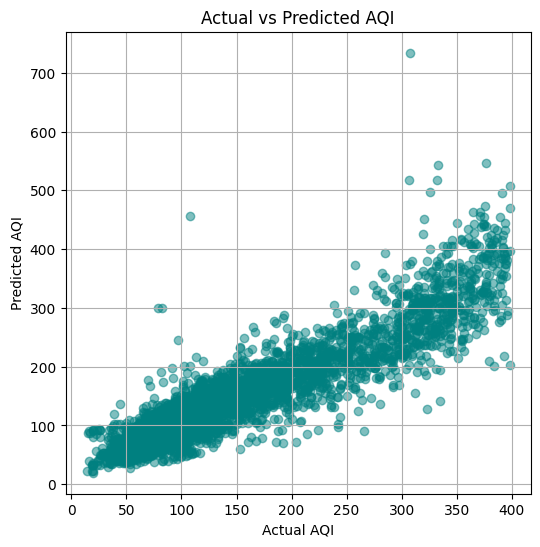

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.grid(True)
plt.show()


C:\Users\malot\AppData\Local\Temp\ipykernel_17200\3510103650.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient", y="Feature", data=coeffs, palette="viridis")


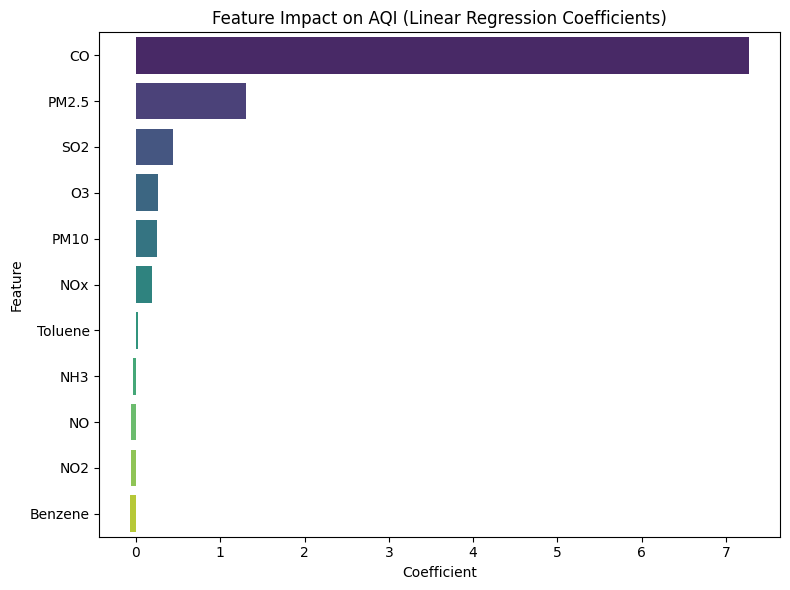

In [7]:
import pandas as pd
import seaborn as sns
import os

coeffs = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x="Coefficient", y="Feature", data=coeffs, palette="viridis")
plt.title("Feature Impact on AQI (Linear Regression Coefficients)")
plt.tight_layout()

os.makedirs("../visuals", exist_ok=True)
plt.savefig("../visuals/feature_importance.png")
plt.show()


In [8]:
import joblib
os.makedirs("../models", exist_ok=True)
joblib.dump(model, "../models/linear_regression_model.pkl")

print("✅ Model saved successfully at '../models/linear_regression_model.pkl'")


✅ Model saved successfully at '../models/linear_regression_model.pkl'


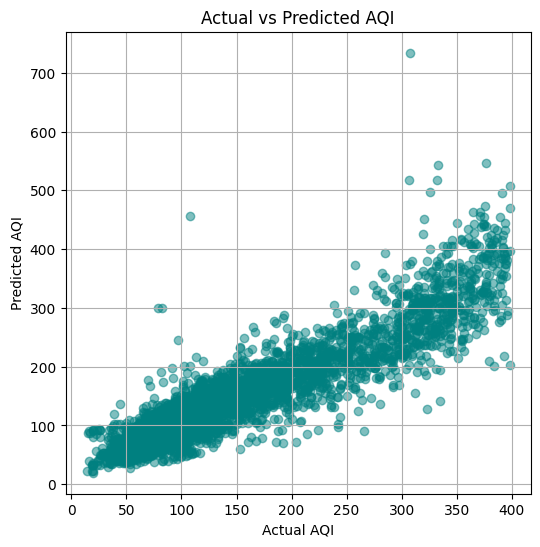

In [9]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.grid(True)

plt.savefig("../visuals/actual_vs_predicted.png")
plt.show()


In [10]:
predictions_df = pd.DataFrame({
    "Actual_AQI": y_test,
    "Predicted_AQI": y_pred
})

predictions_df.to_csv("../visuals/predictions_sample.csv", index=False)
print("✅ Saved sample predictions as '../visuals/predictions_sample.csv'")


✅ Saved sample predictions as '../visuals/predictions_sample.csv'


In [11]:
import joblib, os

# retrain if needed (or reuse your existing 'model' variable)
joblib.dump(model, "../models/linear_regression_model.pkl")

print("✅ Model re-saved successfully!")


✅ Model re-saved successfully!


In [12]:
import os
print(os.listdir("../models"))


['linear_regression_model.pkl']


In [13]:
import joblib

# Load your trained model
model = joblib.load("../models/linear_regression_model.pkl")
print("✅ Model loaded successfully for live prediction!")


✅ Model loaded successfully for live prediction!


In [14]:
# Example input (you can change these numbers live during presentation)
sample_input = [[85, 110, 25, 40, 60, 8, 1.1, 20, 15, 3.0, 7.0]]

# Make prediction
predicted_aqi = model.predict(sample_input)
print(f"🌤️ Predicted AQI: {predicted_aqi[0]:.2f}")


🌤️ Predicted AQI: 177.66


c:\Users\malot\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [19]:
# for quick demo
sample_input = [[85, 110, 30, 40, 60, 8, 1.1, 20, 15, 3.0, 7.0]]

predicted_aqi = model.predict(sample_input)
print(f"Predicted AQI: {predicted_aqi[0]:.2f}")


Predicted AQI: 177.38


c:\Users\malot\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
